# NovaCart ETL Pipeline Demo

## End-to-End Data Pipeline

Our pipeline transforms raw data into reliable, analytics-ready datasets.

### Pipeline Architecture

Raw Sources (CSV / JSON / SQLite)
↓
Bronze Layer — Data Ingestion
↓
Silver Layer — Validation & Deduplication
↓
Gold Layer — Analytics & Reporting

### Key Features
- Multi-source data ingestion
- Data validation and deduplication
- Quarantine for invalid records
- Incremental loading with watermark
- Star schema for analytics
- Pipeline monitoring and logging

In [48]:
PROJECT_ROOT = !git rev-parse --show-toplevel
PROJECT_ROOT = PROJECT_ROOT[0]

%cd {PROJECT_ROOT}

!python scripts/generate_sample_data.py
!python -m src.pipeline --date 2025-11-07

/Users/manat/Desktop/novacart-solution
  wrote /Users/manat/Desktop/novacart-solution/data/landing/orders/orders_2025-11-07.csv
  wrote /Users/manat/Desktop/novacart-solution/data/landing/orders/orders_2025-11-08.csv
  wrote /Users/manat/Desktop/novacart-solution/data/landing/orders/orders_2025-11-09.csv
  wrote /Users/manat/Desktop/novacart-solution/data/landing/orders/orders_2025-11-10.csv
  wrote /Users/manat/Desktop/novacart-solution/data/landing/customers/customers.json
  wrote /Users/manat/Desktop/novacart-solution/data/landing/products.db (4 products)

Sample data generation complete.
Next: python -m src.pipeline --date 2025-11-10 --backfill 3
{"ts": "2026-10-16T02:19:28.596835+00:00", "event": "orders_ingested", "run_id": "4d015afd", "date": "2025-11-07", "stage": "ingest_orders", "rows": 5}
{"ts": "2026-10-16T02:19:28.600212+00:00", "event": "orders_bronze_written", "run_id": "4d015afd", "date": "2025-11-07", "stage": "ingest_orders", "path": "/Users/manat/Desktop/novacart-sol

## 1. Raw Data Sources

NovaCart receives data from three sources:

- Orders: CSV
- Customers: JSON
- Products: SQLite

In [49]:
from pathlib import Path
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path(
    "/Users/manat/Desktop/novacart-solution"
)

print("=== BRONZE LAYER ===")

for source in ["orders", "customers", "products"]:
    source_dir = PROJECT_ROOT / "data/bronze" / source

    files = sorted(source_dir.rglob("*.parquet"))

    print(f"\n--- {source.upper()} ---")

    if not files:
        print("No Parquet files found.")
        continue

    for file in files:
        df = pd.read_parquet(file)

        print("File:", file.relative_to(PROJECT_ROOT))
        print("Rows:", len(df))

        display(df.head(10))

=== BRONZE LAYER ===

--- ORDERS ---
File: data/bronze/orders/date=2025-11-07/data.parquet
Rows: 5


,order_id,customer_id,product_id,order_date,quantity,unit_price,status,_row_hash,_source_file,_ingested_at,_partition_date
0,ORD-001,CUST-001,PROD-001,2025-11-07,2,49.99,shipped,3528f8e7c110811b661d8ed9003e348efd5adff40d6881...,orders_2025-11-07.csv,2026-10-16T02:19:28.598434+00:00,2025-11-07
1,ORD-002,CUST-002,PROD-002,2025-11-07,1,199.00,pending,ee6fcb64eb4dd2d2ff65da6bcc03a87c72a3392a3d3812...,orders_2025-11-07.csv,2026-10-16T02:19:28.598434+00:00,2025-11-07
2,ORD-003,CUST-003,PROD-001,2025-11-07,5,49.99,delivered,9734757b68d7b661e8041e7378d86d35bcffdee00a2583...,orders_2025-11-07.csv,2026-10-16T02:19:28.598434+00:00,2025-11-07
3,ORD-004,CUST-001,PROD-003,2025-11-07,0,29.99,pending,c4c3307aff150728afbdfd44a2682aab7f831ee2c0c169...,orders_2025-11-07.csv,2026-10-16T02:19:28.598434+00:00,2025-11-07
4,ORD-001,CUST-001,PROD-001,2025-11-07,2,49.99,shipped,3528f8e7c110811b661d8ed9003e348efd5adff40d6881...,orders_2025-11-07.csv,2026-10-16T02:19:28.598434+00:00,2025-11-07



--- CUSTOMERS ---
File: data/bronze/customers/data.parquet
Rows: 5


,customer_id,first_name,last_name,email,address,signup_date,tier,_row_hash,_source_file,_ingested_at
0,CUST-001,Alice,Smith,alice@example.com,"{'city': 'New York', 'country': 'US'}",2024-01-15,gold,401a2c661ec89f63c2b2a4b060b17b4bf95373a7cc6f87...,customers.json,2026-10-16T02:19:28.603356+00:00
1,CUST-002,Bob,Jones,bob@example.com,"{'city': 'London', 'country': 'GB'}",2024-03-22,standard,4b920c3186344a3fba8acd31dd5b64da4abe91bef12413...,customers.json,2026-10-16T02:19:28.603356+00:00
2,CUST-003,Carol,White,carol@example.com,"{'city': 'Toronto', 'country': 'CA'}",2023-11-05,silver,a185bc63cfc5d7b45bc2584a0f6554246421dc33ca6158...,customers.json,2026-10-16T02:19:28.603356+00:00
3,CUST-004,Dan,Brown,dan@example.com,"{'city': 'Sydney', 'country': 'AU'}",2024-06-18,standard,946eb9aab5ea2c7fb2aef5482ee5173dc71ef33dd8416f...,customers.json,2026-10-16T02:19:28.603356+00:00
4,CUST-005,Eve,Davis,eve-at-example.com,"{'city': 'Paris', 'country': 'FR'}",2024-08-01,gold,fab66e12b623595b9f905c5a1d3049647601c7b6d5de41...,customers.json,2026-10-16T02:19:28.603356+00:00



--- PRODUCTS ---
File: data/bronze/products/data.parquet
Rows: 4


,product_id,name,category,unit_cost,supplier_id,updated_at,_row_hash,_ingested_at,_source_file
0,PROD-001,Wireless Headphones,Electronics,22.5,SUP-A,2025-10-01T10:00:00,464769cdf55aa25d6c93b54ec98965d77b53cad67c36a9...,2026-10-16T02:03:06.245393+00:00,products.db
1,PROD-002,Laptop Stand,Accessories,8.75,SUP-B,2025-10-15T14:30:00,f6f7cb14c16cec7199afd56252c027b3cd5c3c4a0d9c74...,2026-10-16T02:03:06.245393+00:00,products.db
2,PROD-003,USB-C Hub,Electronics,12.0,SUP-A,2025-11-01T09:00:00,33f58f5563b24b0d03471adb54741000f351c722d118bc...,2026-10-16T02:03:06.245393+00:00,products.db
3,PROD-004,Webcam HD,Electronics,35.0,SUP-C,2025-11-05T11:15:00,c2dd88939a93e0a96a7f5cc6f62ef774fb8ff898843425...,2026-10-16T02:03:06.245393+00:00,products.db


## 3. Silver Layer — Data Quality

The Silver Layer transforms raw data into clean, validated datasets.

### Key Operations
- **Validation:** Validate records using Pydantic.
- **Type Conversion:** Enforce consistent data types.
- **Deduplication:** Keep the latest record for each primary key.
- **Quarantine:** Isolate invalid records with error reasons.

In [50]:
print("=== SILVER LAYER ===")

for source in ["orders", "customers", "products"]:
    source_dir = PROJECT_ROOT / "data/silver" / source
    files = sorted(source_dir.rglob("*.parquet"))

    print(f"\n--- {source.upper()} ---")

    if not files:
        print("No Silver data found.")
        continue

    for file in files:
        df = pd.read_parquet(file)

        print("File:", file.relative_to(PROJECT_ROOT))
        print("Validated Rows:", len(df))

        display(df.head(10))

=== SILVER LAYER ===

--- ORDERS ---
File: data/silver/orders/date=2025-11-07/data.parquet
Validated Rows: 3


,order_id,customer_id,product_id,order_date,quantity,unit_price,status,_row_hash,_source_file,_ingested_at,_partition_date
0,ORD-002,CUST-002,PROD-002,2025-11-07,1,199.00,pending,ee6fcb64eb4dd2d2ff65da6bcc03a87c72a3392a3d3812...,orders_2025-11-07.csv,2026-10-16T02:19:28.598434+00:00,2025-11-07
1,ORD-003,CUST-003,PROD-001,2025-11-07,5,49.99,delivered,9734757b68d7b661e8041e7378d86d35bcffdee00a2583...,orders_2025-11-07.csv,2026-10-16T02:19:28.598434+00:00,2025-11-07
2,ORD-001,CUST-001,PROD-001,2025-11-07,2,49.99,shipped,3528f8e7c110811b661d8ed9003e348efd5adff40d6881...,orders_2025-11-07.csv,2026-10-16T02:19:28.598434+00:00,2025-11-07



--- CUSTOMERS ---
File: data/silver/customers/data.parquet
Validated Rows: 4


,customer_id,first_name,last_name,email,signup_date,tier,_row_hash,_source_file,_ingested_at,city,country
0,CUST-001,Alice,Smith,alice@example.com,2024-01-15,gold,401a2c661ec89f63c2b2a4b060b17b4bf95373a7cc6f87...,customers.json,2026-10-16T02:19:28.603356+00:00,New York,US
1,CUST-002,Bob,Jones,bob@example.com,2024-03-22,standard,4b920c3186344a3fba8acd31dd5b64da4abe91bef12413...,customers.json,2026-10-16T02:19:28.603356+00:00,London,GB
2,CUST-003,Carol,White,carol@example.com,2023-11-05,silver,a185bc63cfc5d7b45bc2584a0f6554246421dc33ca6158...,customers.json,2026-10-16T02:19:28.603356+00:00,Toronto,CA
3,CUST-004,Dan,Brown,dan@example.com,2024-06-18,standard,946eb9aab5ea2c7fb2aef5482ee5173dc71ef33dd8416f...,customers.json,2026-10-16T02:19:28.603356+00:00,Sydney,AU



--- PRODUCTS ---
File: data/silver/products/data.parquet
Validated Rows: 4


,product_id,name,category,unit_cost,supplier_id,updated_at,_row_hash,_ingested_at,_source_file
0,PROD-001,Wireless Headphones,Electronics,22.50,SUP-A,2025-10-01T10:00:00,464769cdf55aa25d6c93b54ec98965d77b53cad67c36a9...,2026-10-16T02:03:06.245393+00:00,products.db
1,PROD-002,Laptop Stand,Accessories,8.75,SUP-B,2025-10-15T14:30:00,f6f7cb14c16cec7199afd56252c027b3cd5c3c4a0d9c74...,2026-10-16T02:03:06.245393+00:00,products.db
2,PROD-003,USB-C Hub,Electronics,12.00,SUP-A,2025-11-01T09:00:00,33f58f5563b24b0d03471adb54741000f351c722d118bc...,2026-10-16T02:03:06.245393+00:00,products.db
3,PROD-004,Webcam HD,Electronics,35.00,SUP-C,2025-11-05T11:15:00,c2dd88939a93e0a96a7f5cc6f62ef774fb8ff898843425...,2026-10-16T02:03:06.245393+00:00,products.db


## 4. Quarantine — Error Handling

Invalid records are isolated instead of being silently dropped.

### Key Features
- Store invalid records separately.
- Record validation errors in `_error_reason`.
- Preserve records for investigation and correction.
- Allow valid records to continue through the pipeline.

In [51]:
print("=== VALIDATION ERROR DETAILS ===")

for source in ["orders", "customers"]:
    files = sorted(
        (PROJECT_ROOT / "data/quarantine" / source).glob("*.parquet"),
        key=lambda p: p.stat().st_mtime
    )

    if not files:
        continue

    df = pd.read_parquet(files[-1])

    for _, row in df.iterrows():
        record_id = row.get(
            "order_id", row.get("customer_id", "Unknown")
        )

        print(f"\nDataset: {source.upper()}")
        print(f"Record: {record_id}")
        print(f"Error: {row['_error_reason']}")
        print("-" * 60)

=== VALIDATION ERROR DETAILS ===

Dataset: ORDERS
Record: ORD-004
Error: 1 validation error for OrderRow
quantity
  Value error, quantity must be > 0, got 0 [type=value_error, input_value='0', input_type=str]
    For further information visit https://errors.pydantic.dev/2.14/v/value_error
------------------------------------------------------------

Dataset: CUSTOMERS
Record: CUST-005
Error: 1 validation error for CustomerRow
email
  Value error, invalid email: eve-at-example.com [type=value_error, input_value='eve-at-example.com', input_type=str]
    For further information visit https://errors.pydantic.dev/2.14/v/value_error
------------------------------------------------------------


## 5. Gold Layer — Business Analytics

The Gold Layer transforms validated Silver data into
analytics-ready tables using a star schema.

### Gold Tables
- **dim_customer:** Customer dimension with SCD Type 2 history
- **dim_product:** Product dimension
- **fact_orders:** Order fact table

In [52]:
print("=== GOLD LAYER ===")

gold_dir = PROJECT_ROOT / "data/gold"

for file in sorted(gold_dir.rglob("*.parquet")):
    df = pd.read_parquet(file)

    print("\nTable:", file.relative_to(gold_dir))
    print("Rows:", len(df))

    display(df.head(10))

=== GOLD LAYER ===

Table: dim_customer.parquet
Rows: 4


,customer_id,first_name,last_name,email,signup_date,tier,city,country,_row_hash,_eff_start,_eff_end,_current
0,CUST-001,Alice,Smith,alice@example.com,2024-01-15,gold,New York,US,a113100a15566c529e77157ec8fdd94a,2025-11-07,9999-12-31,True
1,CUST-002,Bob,Jones,bob@example.com,2024-03-22,standard,London,GB,7bb00767e42b322bfca617e80153a61a,2025-11-07,9999-12-31,True
2,CUST-003,Carol,White,carol@example.com,2023-11-05,silver,Toronto,CA,08141adedbed73ff1b46b89636c91d98,2025-11-07,9999-12-31,True
3,CUST-004,Dan,Brown,dan@example.com,2024-06-18,standard,Sydney,AU,0d3ea0721568088c1fcbb352ffeacc56,2025-11-07,9999-12-31,True



Table: dim_date.parquet
Rows: 1096


,date_key,date,year,quarter,month,month_name,day,day_of_week,day_name,is_weekend
0,20240101,2024-01-01,2024,1,1,January,1,1,Monday,False
1,20240102,2024-01-02,2024,1,1,January,2,2,Tuesday,False
2,20240103,2024-01-03,2024,1,1,January,3,3,Wednesday,False
3,20240104,2024-01-04,2024,1,1,January,4,4,Thursday,False
4,20240105,2024-01-05,2024,1,1,January,5,5,Friday,False
5,20240106,2024-01-06,2024,1,1,January,6,6,Saturday,True
6,20240107,2024-01-07,2024,1,1,January,7,7,Sunday,True
7,20240108,2024-01-08,2024,1,1,January,8,1,Monday,False
8,20240109,2024-01-09,2024,1,1,January,9,2,Tuesday,False
9,20240110,2024-01-10,2024,1,1,January,10,3,Wednesday,False



Table: dim_product.parquet
Rows: 4


,product_id,name,category,unit_cost,supplier_id,updated_at
0,PROD-001,Wireless Headphones,Electronics,22.50,SUP-A,2025-10-01T10:00:00
1,PROD-002,Laptop Stand,Accessories,8.75,SUP-B,2025-10-15T14:30:00
2,PROD-003,USB-C Hub,Electronics,12.00,SUP-A,2025-11-01T09:00:00
3,PROD-004,Webcam HD,Electronics,35.00,SUP-C,2025-11-05T11:15:00



Table: fact_orders/date=2025-11-07/data.parquet
Rows: 3


,order_id,customer_id,product_id,order_date,quantity,unit_price,status,total_amount,date_key,_load_date
0,ORD-001,CUST-001,PROD-001,2025-11-07,2,49.99,shipped,99.98,20251107,2025-11-07
1,ORD-002,CUST-002,PROD-002,2025-11-07,1,199.00,pending,199.00,20251107,2025-11-07
2,ORD-003,CUST-003,PROD-001,2025-11-07,5,49.99,delivered,249.95,20251107,2025-11-07


## 6. Pipeline Monitoring & Observability

Our pipeline tracks execution status, processing time,
record counts, and data quality metrics for each stage.

### Key Capabilities
- Pipeline execution status
- Stage-level logging
- Input and output row counts
- Quarantined record tracking
- Execution time monitoring

In [53]:
import json
import pandas as pd
from IPython.display import display

events = []

for line in result.stderr.splitlines():
    try:
        events.append(json.loads(line))
    except json.JSONDecodeError:
        continue

stages = []

for event in events:
    if event.get("event") == "stage_end":
        stages.append({
            "Stage": event.get("stage"),
            "Status": event.get("status"),
            "Rows In": event.get("rows_in"),
            "Rows Out": event.get("rows_out"),
            "Quarantined": event.get("rows_quarantined", 0),
            "Duration (s)": event.get("duration_sec")
        })

stages_df = pd.DataFrame(stages)

display(stages_df)

,Stage,Status,Rows In,Rows Out,Quarantined,Duration (s)
0,ingest_orders,OK,NaN,5,0,0.006703
1,ingest_customers,OK,NaN,6,0,0.004604
2,ingest_products,OK,NaN,4,0,0.001900
3,silver_orders,OK,5.0,3,1,0.022177
4,silver_customers,OK,6.0,4,2,0.004975
5,silver_products,OK,4.0,4,0,0.002894
6,dim_product,OK,4.0,4,0,0.003671
7,dim_customer,OK,4.0,4,0,0.011652
8,fact_orders,OK,3.0,3,0,0.006654


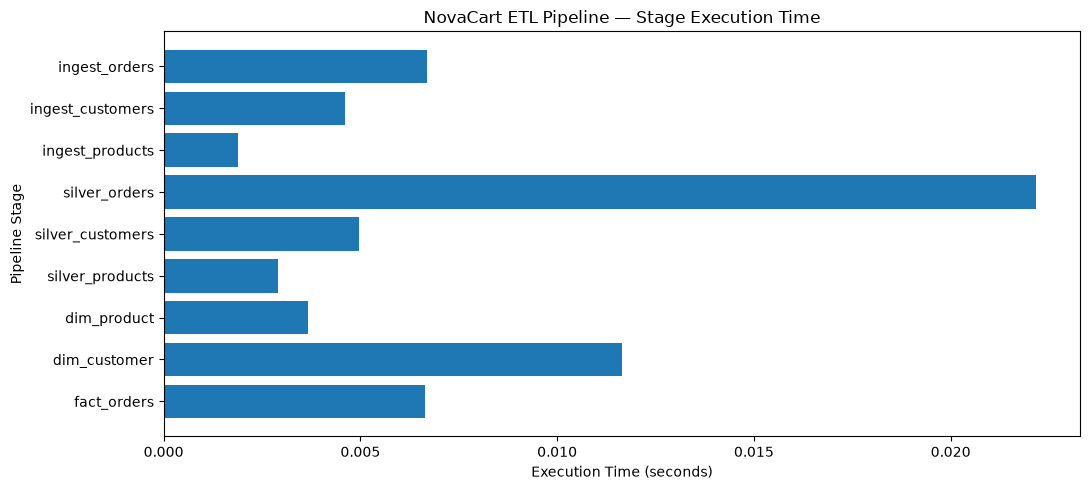

In [54]:
import matplotlib.pyplot as plt

chart_df = stages_df.dropna(subset=["Duration (s)"])

plt.figure(figsize=(11, 5))

plt.barh(
    chart_df["Stage"],
    chart_df["Duration (s)"]
)

plt.xlabel("Execution Time (seconds)")
plt.ylabel("Pipeline Stage")
plt.title("NovaCart ETL Pipeline — Stage Execution Time")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 7. Pipeline Execution Summary

This section summarizes the execution status and performance
of the end-to-end NovaCart ETL Pipeline.

In [55]:
pipeline_events = [
    e for e in events
    if e.get("event") == "pipeline_end"
]

if pipeline_events:
    summary = pipeline_events[-1]

    print("=== NOVACART PIPELINE SUMMARY ===")
    print("Run ID:", summary.get("run_id"))
    print("Status:", summary.get("status"))
    print("Processing Date:", summary.get("date"))
    print("Duration:", summary.get("duration_sec"), "seconds")
    print("Total Stages:", len(stages_df))
    print(
        "Successful Stages:",
        (stages_df["Status"] == "OK").sum()
    )

=== NOVACART PIPELINE SUMMARY ===
Run ID: e2d90481
Status: SUCCESS
Processing Date: 2025-11-07
Duration: 0.071188 seconds
Total Stages: 9
Successful Stages: 9


In [56]:
from pathlib import Path
import sys

# Automatically locate the project root
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

print("Project:", PROJECT_ROOT)
print("Pipeline exists:", (PROJECT_ROOT / "src/pipeline.py").exists())

Project: /Users/manat/Desktop/novacart-solution
Pipeline exists: True


## 8. Emergency Alert System

The Emergency Alert System detects critical structural issues in incoming data — such as a missing required column — before they can corrupt downstream layers.

### Scenario: Missing `last_name` Column in Customer Table

The cell below writes a defective `customers.json` to `data/landing/customers/` where CUST-006 has no `last_name` field, then re-runs the pipeline so the validation layer catches and quarantines the bad record.

In [ ]:
import json
from pathlib import Path

# Resolve project root relative to this notebook — no hardcoded paths
PROJECT_ROOT = !git rev-parse --show-toplevel
PROJECT_ROOT = Path(PROJECT_ROOT[0])

customers_path = PROJECT_ROOT / 'data' / 'landing' / 'customers' / 'customers.json'

defective_customers = [
    {
        "customer_id": "CUST-001",
        "first_name": "Alice",
        "email": "alice@example.com",
        "address": {"city": "New York", "country": "US"},
        "signup_date": "2024-01-15",
        "tier": "gold"
    },
    {
        "customer_id": "CUST-002",
        "first_name": "Bob",
        "email": "bob@example.com",
        "address": {"city": "London", "country": "GB"},
        "signup_date": "2024-03-22",
        "tier": "standard"
    },
    {
        "customer_id": "CUST-003",
        "first_name": "Carol",
        "email": "carol@example.com",
        "address": {"city": "Toronto", "country": "CA"},
        "signup_date": "2023-11-05",
        "tier": "silver"
    },
    {
        "customer_id": "CUST-004",
        "first_name": "Dan",
        "email": "dan@example.com",
        "address": {"city": "Sydney", "country": "AU"},
        "signup_date": "2024-06-18",
        "tier": "standard"
    },
    {
        "customer_id": "CUST-005",
        "first_name": "Eve",
        "email": "eve-at-example.com",
        "address": {"city": "Paris", "country": "FR"},
        "signup_date": "2024-08-01",
        "tier": "gold"
    },
    {
        "customer_id": "CUST-006",
        "first_name": "Frank",
        "email": "frank@example.com",
        "address": {"city": "Berlin", "country": "DE"},
        "signup_date": "2025-01-10",
        "tier": "standard"
    }
]

customers_path.write_text(json.dumps(defective_customers, indent=2))
print('Note: CUST-006 is missing the last_name field — the pipeline should quarantine it.')

Written 6 records to /Users/manat/Desktop/novacart-solution/data/landing/customers/customers.json
Note: CUST-006 is missing the last_name field — the pipeline should quarantine it.


In [58]:
!cd {PROJECT_ROOT} && python -m src.pipeline --date 2025-11-07

{"ts": "2026-10-16T02:20:18.065207+00:00", "event": "orders_ingested", "run_id": "a428a28a", "date": "2025-11-07", "stage": "ingest_orders", "rows": 5}
{"ts": "2026-10-16T02:20:18.068932+00:00", "event": "orders_bronze_written", "run_id": "a428a28a", "date": "2025-11-07", "stage": "ingest_orders", "path": "/Users/manat/Desktop/novacart-solution/data/bronze/orders/date=2025-11-07/data.parquet", "rows": 5}
{"ts": "2026-10-16T02:20:18.069150+00:00", "event": "stage_end", "run_id": "a428a28a", "date": "2025-11-07", "stage": "ingest_orders", "status": "OK", "rows_in": null, "rows_out": 5, "duration_sec": 0.006108}
{"ts": "2026-10-16T02:20:18.071240+00:00", "event": "customers_ingested", "run_id": "a428a28a", "date": "2025-11-07", "stage": "ingest_customers", "rows": 6}
{"ts": "2026-10-16T02:20:18.072716+00:00", "event": "customers_bronze_written", "run_id": "a428a28a", "date": "2025-11-07", "stage": "ingest_customers", "path": "/Users/manat/Desktop/novacart-solution/data/bronze/customers/da